In [1]:
import os
import glob
import math

import numpy as np
import torch
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import art3d
from matplotlib.patches import Patch

from pytorch3d.io import load_obj

import robust_laplacian
from scipy.sparse.linalg import eigsh

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
print("device:", device)

device: cuda:0


In [2]:
path = "human_seg"

source = lambda p: os.path.basename(p).split("__")[0]
train_data = sorted(glob.glob(f"{path}/train/*.obj"))
test_data = sorted(glob.glob(f"{path}/test*.obj"))

CLASS_NAMES = ["head", "hand", "forearm", "upper arm", "torso", "thigh", "shin", "foot"]
NUM_CLASSES = len(CLASS_NAMES)

COLORS = torch.tensor([
    [0.80, 0.30, 0.30], 
    [0.30, 0.70, 0.30], 
    [0.30, 0.45, 0.90],
    [0.95, 0.75, 0.20],
    [0.70, 0.35, 0.85],
    [0.20, 0.80, 0.80],
    [0.95, 0.55, 0.15],
    [0.60, 0.60, 0.60],
])

In [33]:
def get_ids_from_edges(faces):
    edge_ids = {}
    for face in faces.tolist():
        edges = [ 
            (face[0], face[1]),
            (face[1], face[2]),
            (face[2], face[0])
        ]

        for e in edges:
            e = tuple(sorted(e))

            if e not in edge_ids:
                edge_ids[e] = len(edge_ids)
                
    return edge_ids
            
    
def get_face_labels_from_edges(faces, edge_labels):
    edge_id = get_ids_from_edges(faces)
    assert len(edge_id) == len(edge_labels)
    face_labels = []

    for face in faces.tolist():
        labels = []
        for k in range(3):
            v1 = face[k]
            v2 = face[(k + 1) % 3]

            edge = tuple(sorted((v1, v2)))
            index = edge_id[edge]

            labels.append(edge_labels[index])

        if labels[0] == labels[1] or labels[0] == labels[2]:
            label = labels[0]
        elif labels[1] == labels[2]:
            label = labels[1]
        else:
            label = labels[0]

        face_labels.append(label)

    return torch.tensor(face_labels) - 1 


def compute_areas(V, faces):
    v1 = V[faces[:, 0]]
    v2 = V[faces[:, 1]]
    v3 = V[faces[:, 2]]

    e1 = v2 - v1
    e2 = v3 - v1

    return 0.5 * torch.linalg.cross(e1, e2).norm(dim=1)
    
    
def load_example(obj_path):
    verts, faces, _ = load_obj(obj_path, load_textures=False)
    V, Fc = verts.double(), faces.verts_idx.long()
    
    name = os.path.splitext(os.path.basename(obj_path))[0]
    edge_labels = np.loadtxt(f"{path}/seg/{name}.eseg", dtype=np.int64)
    labels = get_face_labels_from_edges(Fc, edge_labels)

    A = compute_areas(V, Fc)
    face_centers = (V[Fc[:, 0]] + V[Fc[:, 1]] + V[Fc[:, 2]]) / 3
    weighted_centers = face_centers * A[:, None]

    centroid = weighted_centers.sum(dim=0) / A.sum()
    V -= centroid
    V /= A.sum()

    return {"name": name, "V": V, "Fc": Fc, "labels": labels}


def draw_mesh(ax, ex, COLORS, elev=10, azim=40):
    V = ex["V"].detach().cpu().numpy()
    Fc = ex["Fc"].detach().cpu().numpy()
    C = ex["labels"].detach().cpu().numpy()
    colors = COLORS.detach().cpu().numpy()[C]

    mesh = art3d.Poly3DCollection(V[Fc], facecolors=colors, edgecolor="black", linewidth=0.1)
    ax.add_collection3d(mesh)

    mins, maxs = V.min(axis=0), V.max(axis=0)
    center, radius = (mins + maxs) / 2, (maxs - mins).max() / 2
    ax.set_xlim(center[0] - radius, center[0] + radius)
    ax.set_ylim(center[1] - radius, center[1] + radius)
    ax.set_zlim(center[2] - radius, center[2] + radius)
    ax.set_box_aspect((1, 1, 1))
    ax.set_axis_off()
    ax.view_init(elev=elev, azim=azim, vertical_axis="y")


def plot_sample(ex, COLORS, figsize=(6, 6), elev=10, azim=40):
    fig = plt.figure(figsize=figsize)
    ax = fig.add_subplot(111, projection="3d")
    draw_mesh(ax, ex, COLORS, elev, azim)
    plt.show()


def plot_samples(train_data, test_data, COLORS, ncols=4, size=4, elev=10, azim=40):
    picks = {}
    for p in train_data + test_data:
        picks.setdefault(source(p), p)

    n = len(picks)
    nrows = math.ceil(n / ncols)
    fig = plt.figure(figsize=(size * ncols, size * nrows + 1))

    for i, (src, obj_path) in enumerate(picks.items()):
        ax = fig.add_subplot(nrows, ncols, i + 1, projection="3d")
        # draw_mesh(ax, load_example(obj_path), COLORS, elev, azim)
        draw_mesh(ax, bring_to_same_frame(load_example(obj_path)), COLORS, elev, azim)
        ax.set_title(src, fontsize=10)

    palette = COLORS.detach().cpu().numpy()
    handles = [Patch(facecolor=palette[i], label=CLASS_NAMES[i])
               for i in range(NUM_CLASSES)]
    fig.legend(handles=handles, loc="lower center", ncol=NUM_CLASSES,
               fontsize=9, frameon=False)

    plt.tight_layout(rect=(0, 0.05, 1, 1))
    plt.savefig("samples.png", dpi=300, bbox_inches="tight")
    plt.show()


def bring_to_same_frame(ex):
    V = ex["V"]
    Fc = ex["Fc"]
    labels = ex["labels"]
    centers = V[Fc].mean(1)
    part = lambda i: centers[labels == i].mean(0)
    
    head, shin, foot = part(0), part(6), part(7)
    y = head - foot
    y = y / y.norm() # up

    z = foot - shin
    z -= (z @ y) * y
    z /= z.norm() # forward

    x = torch.linalg.cross(y,z)
    R = torch.stack([x,y,z], 1)

    return {**ex, "V": V @ R}


def hks(evals, evecs, t):
    decay = torch.exp(-evals[:, None] * t[None, :])
    h = (evecs ** 2) @ decay 
    return torch.log(h / decay.sum(0, keepdim=True) + 1e-12)

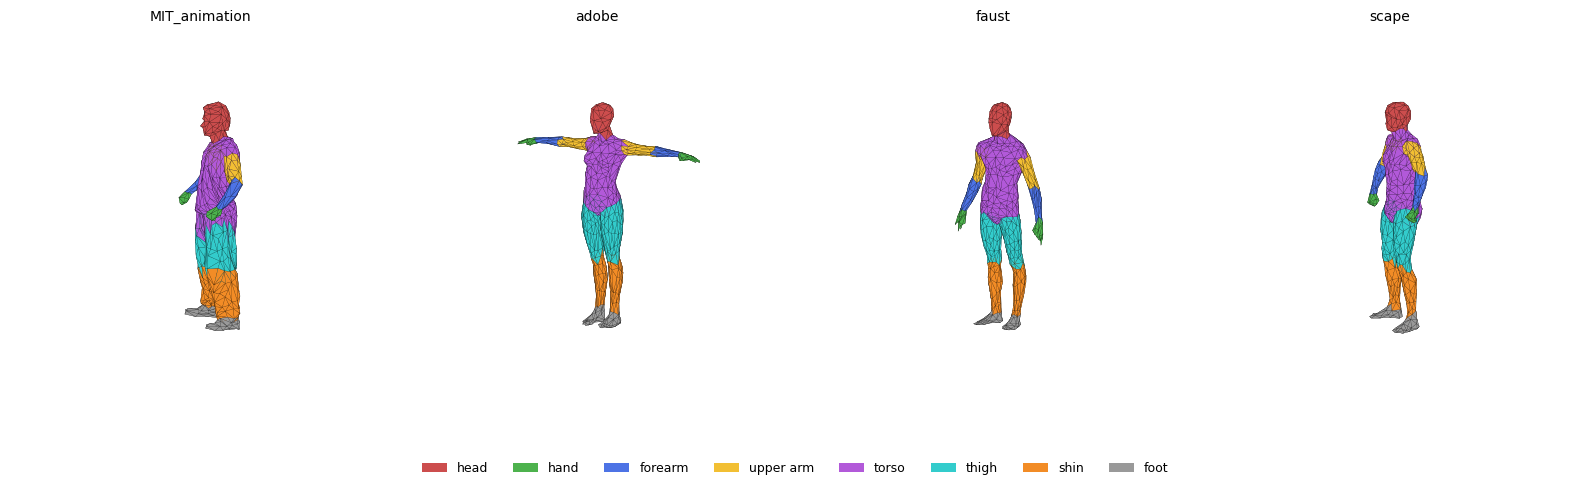

In [34]:
plot_samples(train_data, test_data, COLORS, ncols=4)

In [35]:
ex = bring_to_same_frame(load_example(train_data[105]))
V, Fc = ex["V"], ex["Fc"]
V = V / torch.sqrt(compute_areas(V, Fc).sum())

# spectrum
L, M = robust_laplacian.mesh_laplacian(V.numpy(), Fc.numpy())
evals, evecs = eigsh(L, k=128, M=M, sigma=-1e-8)

# drop constant eigenvalues and eigenvalues
evals = torch.from_numpy(evals).clamp(min=0)[1:]
evecs = torch.from_numpy(evecs)[:, 1:]

t = torch.logspace(-2, 0, 16, dtype=torch.float64)
H = hks(evals, evecs, t)
face_feat = H[Fc].mean(1)

In [36]:
def plot_eigenvectors(V, Fc, evecs, evals, ks):
    fig = plt.figure(figsize=(12, 6))

    V = np.asarray(V)
    Fc = np.asarray(Fc)

    for i, k in enumerate(ks):
        ax = fig.add_subplot(2, 4, i + 1, projection="3d")

        f = evecs[:, k]
        ff = f[Fc].mean(axis=1)
        
        ff = ff.detach().cpu().numpy()

        m = np.abs(ff).max()
        colors = plt.cm.RdBu_r(plt.Normalize(-m, m)(ff))

        mesh = art3d.Poly3DCollection(V[Fc], facecolors=colors, edgecolor="none")

        ax.add_collection3d(mesh)

        mins = V.min(axis=0)
        maxs = V.max(axis=0)
        
        center = (mins + maxs) / 2
        radius = (maxs - mins).max() / 2

        ax.set_xlim(center[0]-radius, center[0]+radius)
        ax.set_ylim(center[1]-radius, center[1]+radius)
        ax.set_zlim(center[2]-radius, center[2]+radius)

        ax.set_box_aspect((1, 1, 1))
        ax.set_axis_off()
        ax.view_init(elev=10, azim=40, vertical_axis="y")

        ax.set_title(f"$\\phi_{{{k+1}}}$, $\\lambda$={evals[k]:.2f}")

    plt.tight_layout()
    plt.show()

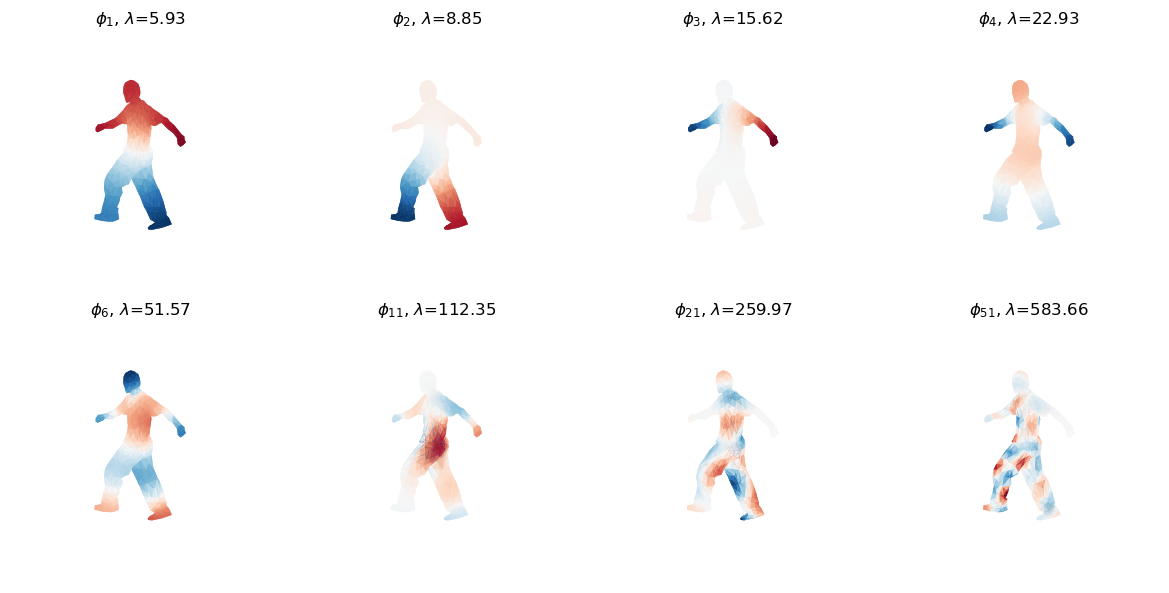

In [37]:
ks = [0, 1, 2, 3, 5, 10, 20, 50]
plot_eigenvectors(V, Fc, evecs, evals, ks)

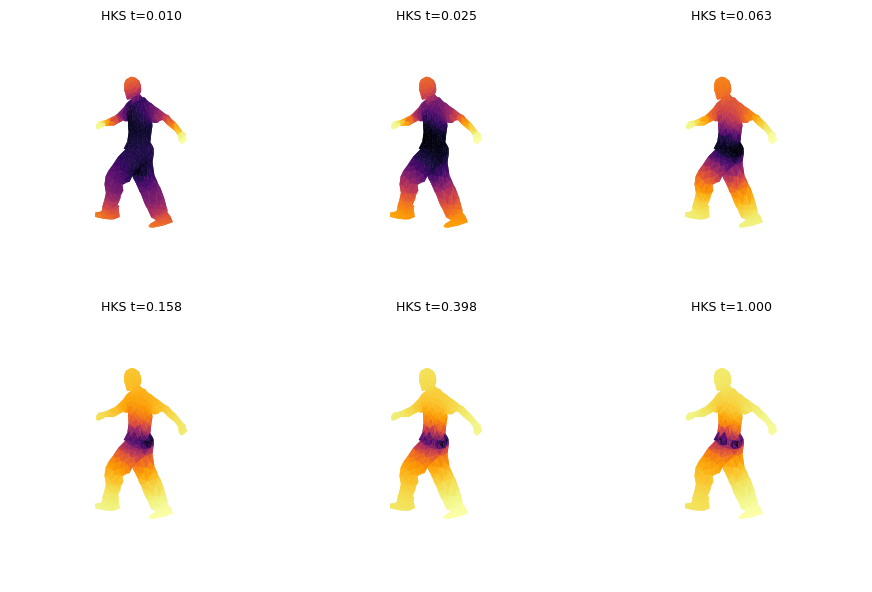

In [16]:
ts = [0, 3, 6, 9, 12, 15]
plot_grid(V, Fc, [H[:, j] for j in ts], [f"HKS t={times[j]:.3f}" for j in ts], cmap="inferno", ncols=3)